# [RQ_2 · HỖ TRỢ] Thí nghiệm cấu hình A — So sánh 4 mô hình hồi quy

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


## 1. Nạp thư viện

In [11]:
from pathlib import Path
from datetime import datetime
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Đọc dữ liệu

In [12]:
hien_tai = Path.cwd().resolve()
ung_vien = [hien_tai, *hien_tai.parents, hien_tai / 'metro_interstate_traffic_volume']
du_an = next((p for p in ung_vien
               if (p / 'data/processed/train.csv').is_file()), None)
if du_an is None:
    raise FileNotFoundError('Không thấy data/processed/train.csv. Hãy mở notebook trong thư mục dự án.')
file_train = du_an / 'data/processed/train.csv'
file_val = du_an / 'data/processed/validation.csv'
import sys
if str(du_an) not in sys.path:
    sys.path.insert(0, str(du_an))
from src.experiment_data import load_experiment_splits

data_splits = load_experiment_splits(project_dir=du_an)
train, validation = data_splits["train"], data_splits["validation"]
cot_thoi_gian = ['hour', 'day_of_week', 'month']
cot_ngay_le = ['is_weekend', 'is_holiday'] + [c for c in train.columns if c.startswith('holiday_')]
cot_dau_vao = cot_thoi_gian + cot_ngay_le
cot_can_du_doan = 'traffic_volume'
if train.columns.tolist() != validation.columns.tolist():
    raise ValueError('Hai file không có cùng danh sách cột. Hãy kiểm tra lại dữ liệu.')
for ten, data in [('train', train), ('validation', validation)]:
    if data[cot_dau_vao + [cot_can_du_doan, 'date_time']].isna().any().any():
        raise ValueError(f'{ten} có dữ liệu bị thiếu ở những cột đang dùng.')
    if data.date_time.duplicated().any() or not data.date_time.is_monotonic_increasing:
        raise ValueError(f'{ten} có thời điểm trùng hoặc chưa sắp tăng dần.')
if train.date_time.max() >= validation.date_time.min():
    raise ValueError('Train và validation bị chồng lấn hoặc sai thứ tự thời gian.')
X_train, y_train = train[cot_dau_vao], train[cot_can_du_doan]
X_val, y_val = validation[cot_dau_vao], validation[cot_can_du_doan]
print(f'Train: {len(train):,} dòng | Validation: {len(validation):,} dòng')
print(f'Train kết thúc: {train.date_time.max()} | Validation bắt đầu: {validation.date_time.min()}')
ma_train = hashlib.sha256(file_train.read_bytes()).hexdigest()
ma_val = hashlib.sha256(file_val.read_bytes()).hexdigest()
if (ma_train == 'f7693e70c29feb9502209f5bfbfd67066ad3466b8b718eb242a1d42a931c37e9'
        and ma_val == 'badbebc15f324ac942bd62cc93b95f853b67584646ed097600f536e03513c4e0'):
    print('Hai file dữ liệu trùng với lần chạy mẫu.')
else:
    print('Lưu ý: dữ liệu khác lần chạy mẫu, nên không so sánh trực tiếp các con số cũ.')

Train: 28,402 dòng | Validation: 6,086 dòng
Train kết thúc: 2017-05-10 04:00:00 | Validation bắt đầu: 2017-05-10 05:00:00
Hai file dữ liệu trùng với lần chạy mẫu.


## 3. Chuẩn bị đầu vào

In [13]:
xu_ly_du_lieu = ColumnTransformer([
    ('thoi_gian', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cot_thoi_gian),
    ('ngay_le', 'passthrough', cot_ngay_le),
])

## 4. Khai báo bốn mô hình

In [14]:
cac_mo_hinh = {
    'Linear Regression': LinearRegression(),

    'Random Forest': RandomForestRegressor(
        n_estimators=200, max_depth=16, min_samples_leaf=3,
        random_state=42, n_jobs=2),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3,
        min_samples_leaf=3, random_state=42),

    'MLP': TransformedTargetRegressor(
        regressor=MLPRegressor(
            hidden_layer_sizes=(64, 32), alpha=0.0001,
            learning_rate_init=0.001, batch_size=256,
            max_iter=500, random_state=42),
        transformer=StandardScaler()),
}

## 5. Huấn luyện và đánh giá

In [15]:
ket_qua = []
du_doan_cac_mo_hinh = {}
for ten, mo_hinh in cac_mo_hinh.items():
    quy_trinh = Pipeline([('xu_ly', clone(xu_ly_du_lieu)), ('mo_hinh', mo_hinh)])
    quy_trinh.fit(X_train, y_train)
    du_doan = np.clip(quy_trinh.predict(X_val), 0, None)
    du_doan_cac_mo_hinh[ten] = du_doan
    ket_qua.append({
        'Mô hình': ten,
        'MAE': mean_absolute_error(y_val, du_doan),
        'RMSE': np.sqrt(mean_squared_error(y_val, du_doan)),
        'R²': r2_score(y_val, du_doan),
    })

bang_ket_qua = pd.DataFrame(ket_qua).sort_values('MAE').reset_index(drop=True)
display(HTML(bang_ket_qua.to_html(
    index=False,
    formatters={
        'MAE': '{:.3f}'.format,
        'RMSE': '{:.3f}'.format,
        'R²': '{:.4f}'.format,
    }
)))

Mô hình,MAE,RMSE,R²
MLP,232.197,359.991,0.9665
Random Forest,312.801,467.374,0.9435
Gradient Boosting,421.867,575.612,0.9143
Linear Regression,555.927,754.247,0.8528


## 6. Vẽ hình so sánh

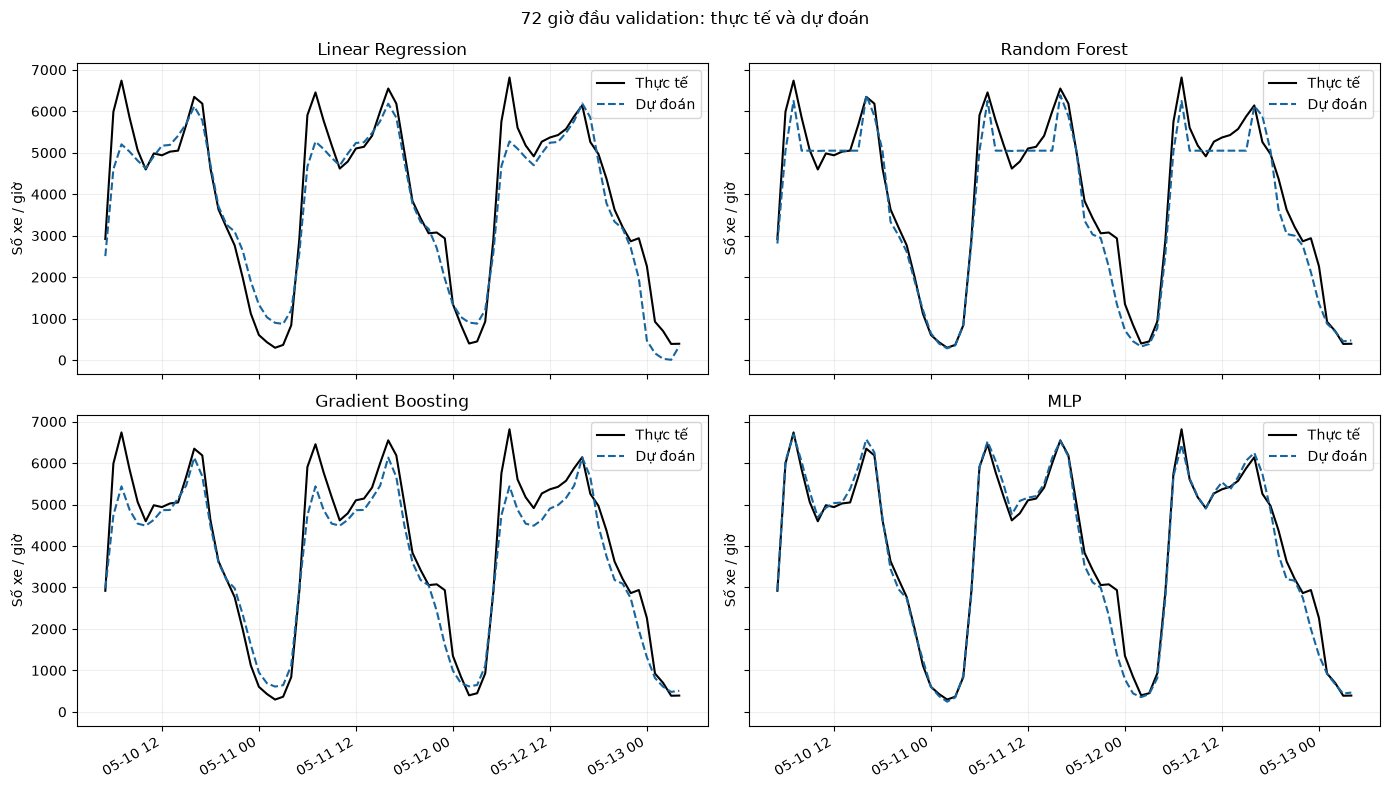

Hình đã lưu tại: /workspaces/SGU_HocMay_2026-2027/metro_interstate_traffic_volume/experiments/12-11_ConfigA_4Model/ConfigA_tinh_chinh_20261112_140304_504718.png


In [7]:
mask_72h = validation.date_time < validation.date_time.min() + pd.Timedelta(hours=72)
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for ax, (ten, du_doan) in zip(axes.flat, du_doan_cac_mo_hinh.items()):
    ax.plot(validation.loc[mask_72h, 'date_time'], y_val.loc[mask_72h],
            color='black', label='Thực tế')
    ax.plot(validation.loc[mask_72h, 'date_time'], du_doan[mask_72h.to_numpy()],
            color='#17659e', linestyle='--', label='Dự đoán')
    ax.set_title(ten)
    ax.set_ylabel('Số xe / giờ')
    ax.grid(alpha=0.2)
    ax.legend()
fig.suptitle('72 giờ đầu validation: thực tế và dự đoán')
fig.autofmt_xdate()
fig.tight_layout()
ten_hinh = Path.cwd() / f"ConfigA_tinh_chinh_{datetime.now():%Y%m%d_%H%M%S_%f}.png"
fig.savefig(ten_hinh, dpi=150, bbox_inches='tight')
plt.show()
print('Hình đã lưu tại:', ten_hinh)

<!-- proposal-assessment -->
## Đánh giá đối với proposal — RQ_2

**Vai trò: HỖ TRỢ.** Mã đối chiếu: [E04](../../docs/experiment_tracking/EXPERIMENTS_BY_DATE_AND_RQ.md). 

- **Câu hỏi:** So sánh pipeline chỉ dùng thời gian/ngày lễ; lập mốc cho B của Hào.
- **Đánh giá:** Lập mốc A17 của nhánh Hào để đối chiếu B71 trong notebook kế tiếp. MLP đạt MAE 232,197 và RMSE 359,991 trong lượt đã lưu.
- **Giới hạn kết luận:** A17 có nhãn lễ chi tiết và encoding riêng, khác A12. Chỉ đo tác dụng thời tiết khi giữ đúng cohort và pipeline phần A giữa hai notebook.
- **Bằng chứng:** [E04: V1_Config_Hao.xlsx](V1_Config_Hao.xlsx).

Đánh giá trên dựa vào hiện vật lịch sử đã đối chứng, không phải kết quả chạy mới. Code lấy dữ liệu đã được chuẩn hóa; chưa huấn luyện lại hoặc chấm test.
